# Predicting data science salaries: from a messy first pass to a defensible model

A redo of the PSTAT 131 R project (`main.Rmd`). The questions here:

1. How much of the original result survives honest evaluation, and what does each cleaning and optimization step buy?
2. Which model is best, decided by a rule fixed *before* looking at the results?
3. What can a business actually do with a model like this?

Every number below comes from `outputs/` (written by `experiments.py` and `insights.py`), under one protocol: 5-fold cross-validation repeated 3 times, cleaning learned on training folds only, scores always computed on untouched held-out rows.

3,755 raw rows -> 2,583 after removing exact duplicates


### Headline
- **The R-style setup looked better than it was.** Random forest on the raw data scored R² **0.40** / RMSE **\$48,832**, but 31% of rows were duplicates leaking across train and test.
- **Honest baseline:** after deduplicating, the same model scores R² **0.39** / RMSE **\$52,356**.
- **After cleaning, features and tuning** the best random forest reaches R² **0.40** and the best boosted model R² **0.41**. The overall winner, **Stacking**, reaches R² **0.41** / RMSE **\$51,366**.
- **The ceiling is the data, not the method:** the model sees seven columns, and people with identical profiles differ in salary by about 30% (section 4).


## 1. The data

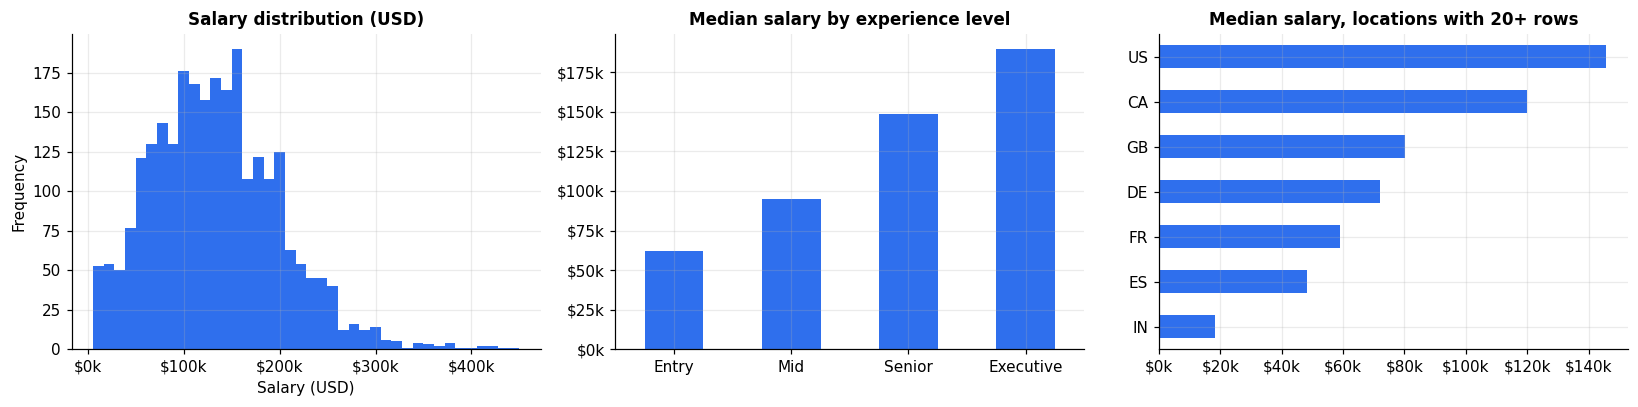

Salaries are right-skewed, rise steeply with experience, and differ hugely by country. Three quarters of rows are US companies, so most other locations are thin.

## 2. Data cleaning log
What was changed, why, and what it cost or bought. Steps that learn from the data (rare-category sets, tail quantiles) are fit on training folds only.

Step,Why,Effect on held-out scores
"Drop salary, salary_currency, employee_residence",Redundant with salary_in_usd and company_location,Not tested separately
Remove exact duplicate rows,"1,172 rows (31%) appear more than once and leak across train/test",Scores get worse but honest
"Model log(salary), convert back to USD",Errors become proportional to salary instead of dominated by the highest earners,Mixed: see stage 2
Collapse rare titles and locations (<10 rows),64 of 93 titles and 59 of 72 locations too thin to learn from,Small
"Add job family, region, level ordinal",Groups 93 titles into 7 families and 72 locations into 6 regions,Small
Trim the top and bottom 1% of salaries in training only,Extreme rows pull fits; held-out rows are never trimmed,Small


A note on trimming: dropping extreme salaries from the **test** rows too makes any model look much better (in a quick test RMSE fell by roughly \$5k), but that is a different, easier question. Trimming is therefore applied to training rows only, and every score is measured on the original held-out rows.

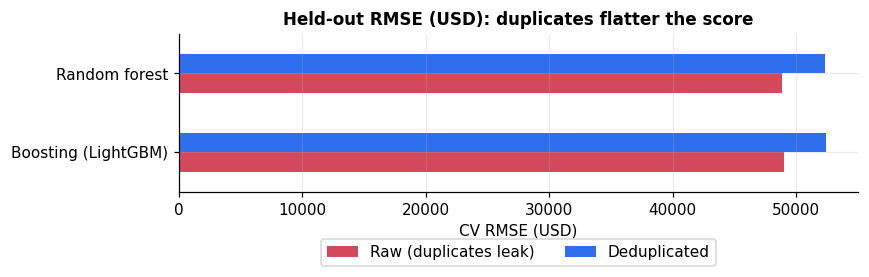

## 3. The progress, at a glance

**The short version.** The original R report plotted predictions on the *training* rows, where a flexible model looks excellent. Held-out scoring on the cleaned data tells a more modest and more trustworthy story. This section shows that gap, then walks through each step one stage at a time (section 3.3 onwards).

helpers ready


### 3.1 Before and after

**Left to right:** the training-fit plot hugs the diagonal (R² **0.57**) because the model has seen those exact rows. Scored honestly the same model reaches R² **0.39**, and after every improvement in this notebook R² **0.41**. The final plot is the one to trust: it uses only rows the model never saw. The gap between the left and middle panel is overfitting; the small gain between the middle and right panel is everything we could do with seven columns.

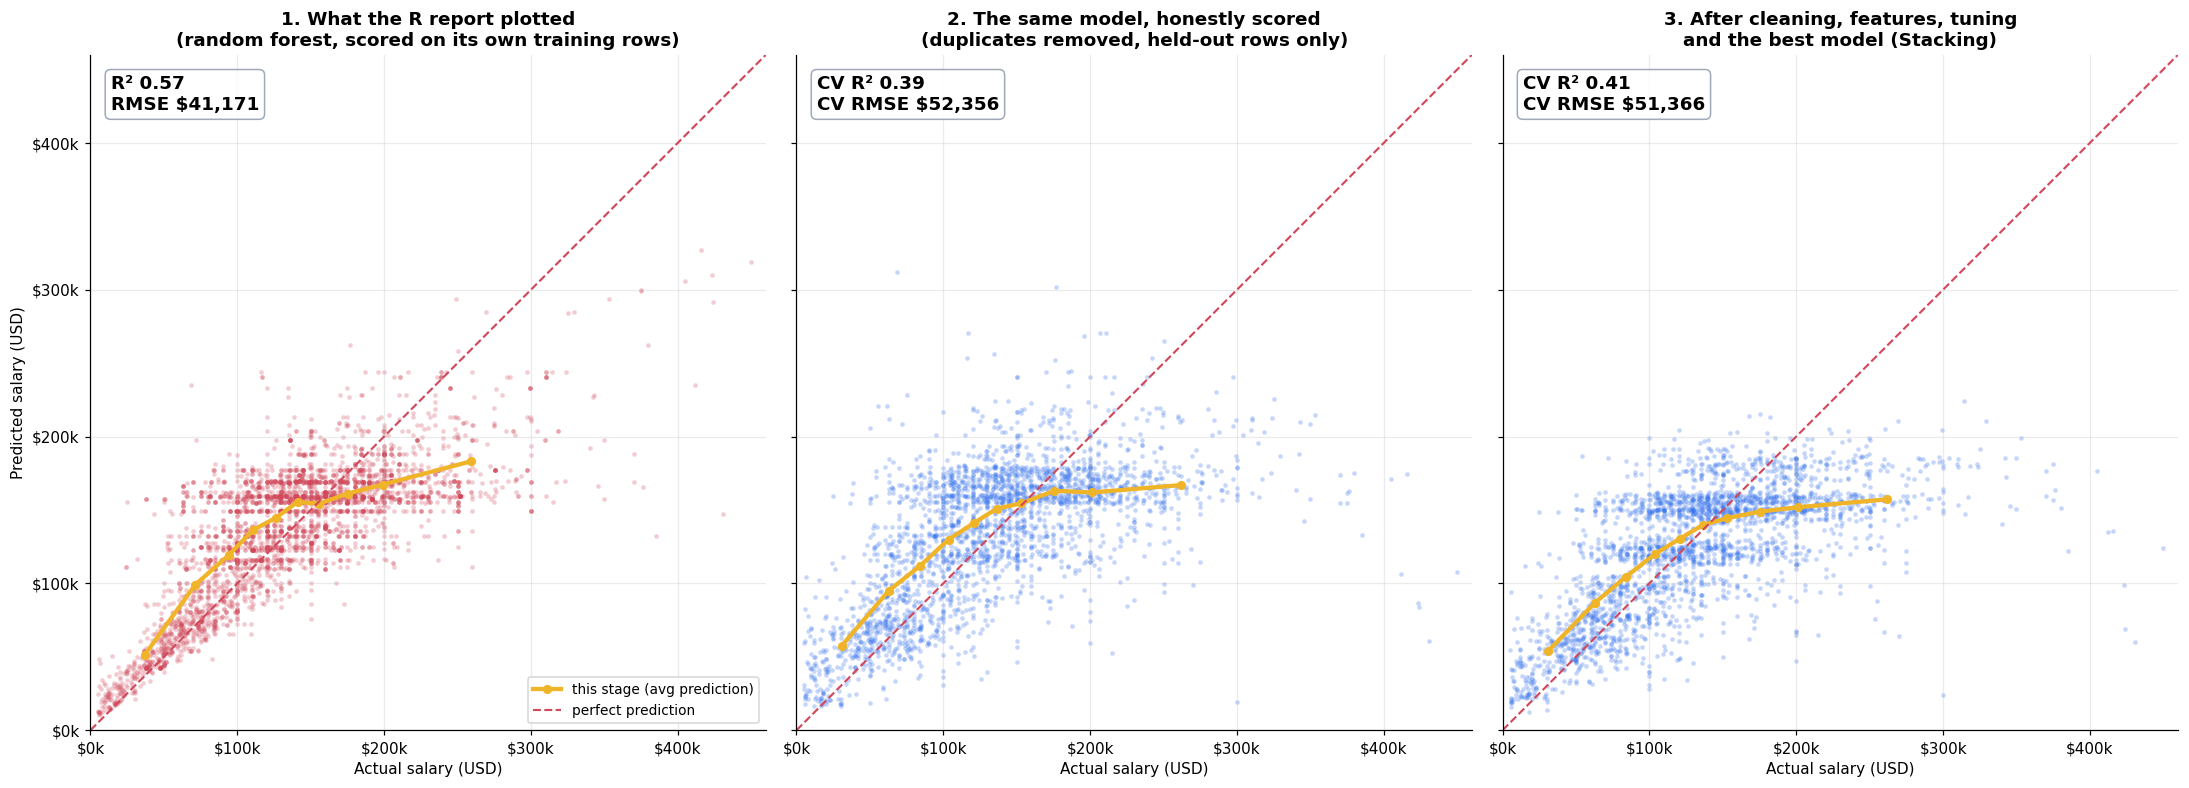

### 3.2 Scoreboard
Every stage, scored on held-out rows. **Δ** columns compare with the previous stage of the same model family. Stage 0 is measured on a different, leaky test set (grey, italic), so its Δ to stage 1 is a correction, not a regression.

Stage,Model,RMSE,MAE,R2,dRMSE,dR2
"0 Raw (R-style, leaky)",Random forest,"$48,832","$36,037",0.398,,
1 Deduplicate,Random forest,"$52,356","$38,433",0.389,"+3,524",-0.009
2 Log target,Random forest,"$52,623","$37,946",0.382,+267,-0.006
3 Clean + features,Random forest,"$52,351","$37,872",0.389,-271,+0.006
4 Tuned,Random forest,"$51,782","$37,239",0.402,-569,+0.013
"0 Raw (R-style, leaky)",Boosting (LightGBM),"$49,033","$36,581",0.393,,
1 Deduplicate,Boosting (LightGBM),"$52,401","$38,826",0.387,"+3,368",-0.005
2 Log target,Boosting (LightGBM),"$53,206","$38,457",0.368,+804,-0.019
3 Clean + features,Boosting (LightGBM),"$52,140","$37,631",0.394,"-1,066",+0.026
4 Tuned,Boosting (LightGBM),"$51,426","$36,879",0.410,-714,+0.016


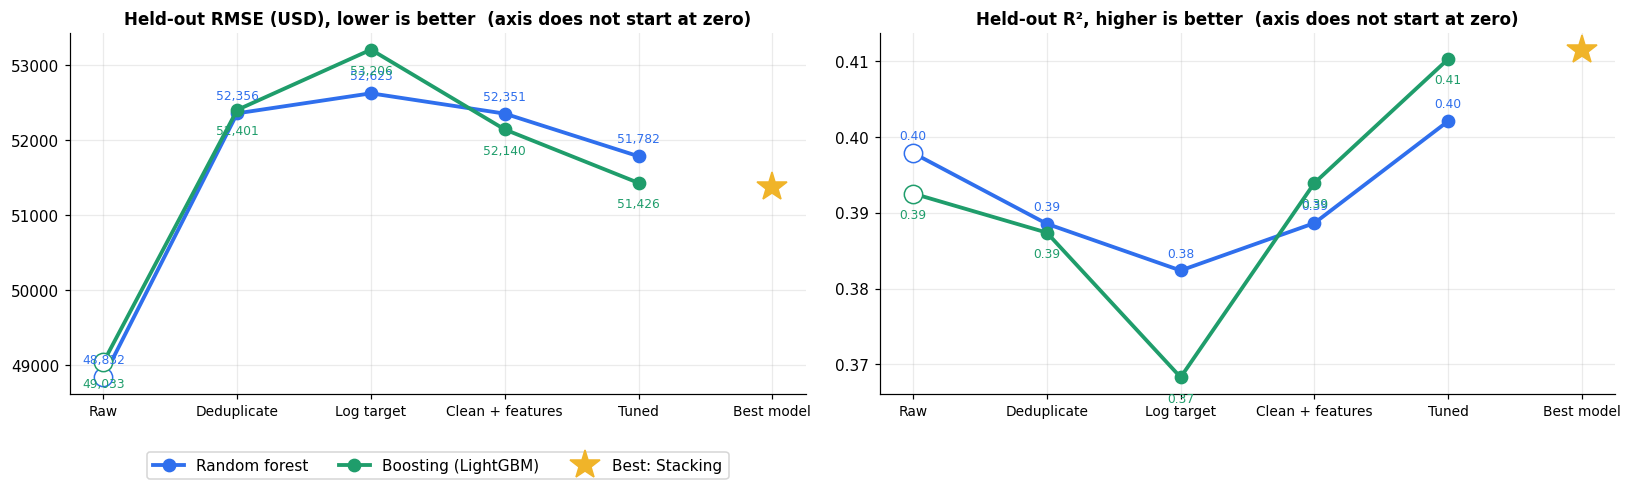

The hollow stage-0 markers sit on a leaky test set; stage 1 is the honest starting line. The route back up is real but modest, which is the honest ceiling of a seven-column dataset.

### 3.3 Stage by stage
Each large plot below shows that stage's out-of-fold predictions for **random forest (left)** and **boosting (right)**. The **gold line** is the average prediction within deciles of the actual salary; the **grey dashed line** is where that line sat at the previous stage, so you can see what the step moved. The closer the gold line is to the red diagonal, the better the model tracks high and low earners.

stage helpers ready


#### Stage 0: the R-style starting point
**What we did:** the data exactly as the R project used it: all 3,755 rows including duplicates, original columns one-hot encoded, salary modelled in dollars, untuned random forest and default boosting.
**Why it is not trustworthy:** copies of the same person can sit in both the training and the test fold, so held-out scores look better than they are.

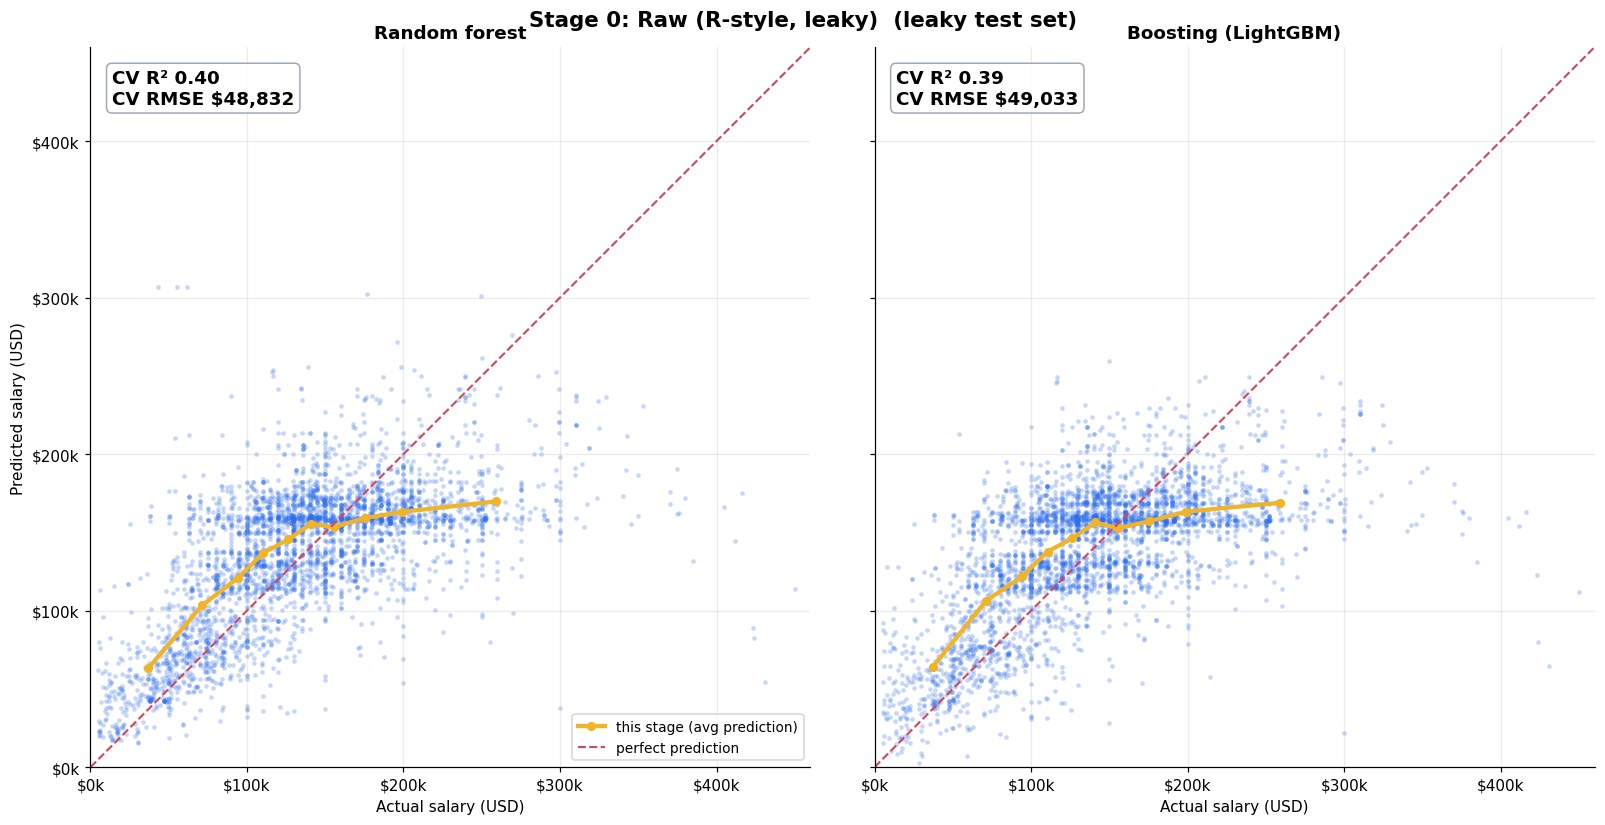

**Result (starting point):** **Random forest:** RMSE \$48,832, R² 0.398 | **Boosting:** RMSE \$49,033, R² 0.393  
The model has effectively seen many of the rows it is scored on, so these scores are the most optimistic ones in the notebook.

#### Stage 1: remove duplicate rows
**What we did:** dropped the 1,172 exact duplicates (31%). Nothing else changed.
**What to expect:** worse scores. This is a correction, not an optimisation.

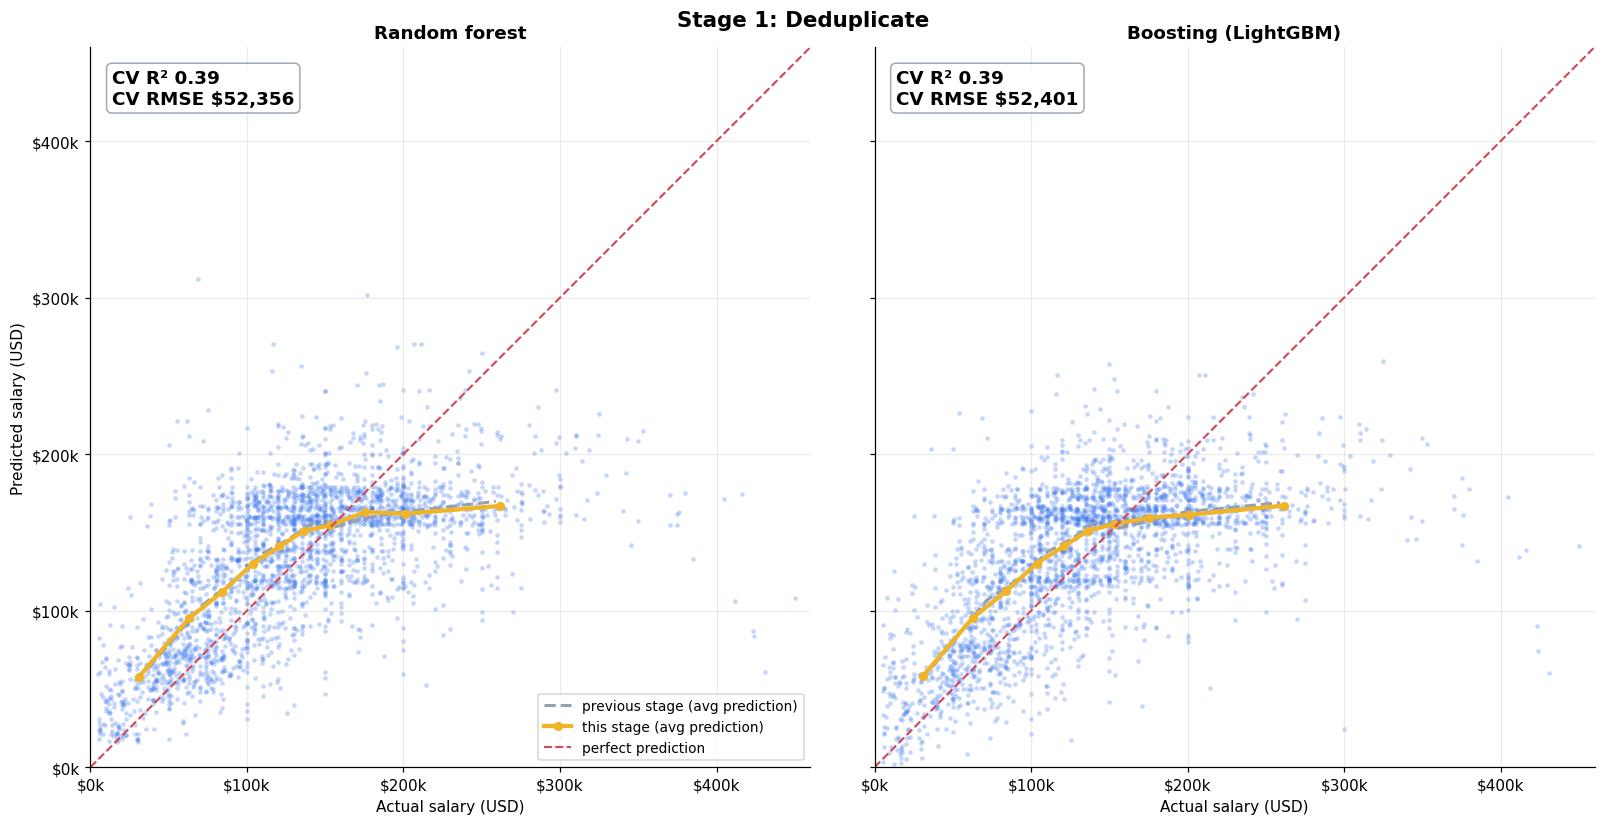

**Result (**hurt**):** **Random forest:** RMSE \$52,356 (+3,524), R² 0.389 (-0.009) | **Boosting:** RMSE \$52,401 (+3,368), R² 0.387 (-0.005)  
Scores fall because the leak is gone. This is the honest baseline: every later number is measured against it.

#### Stage 2: model log-salary
**What we did:** predict log(salary) and convert back to dollars, so errors are proportional to pay instead of dominated by the highest earners. This normally helps linear models.

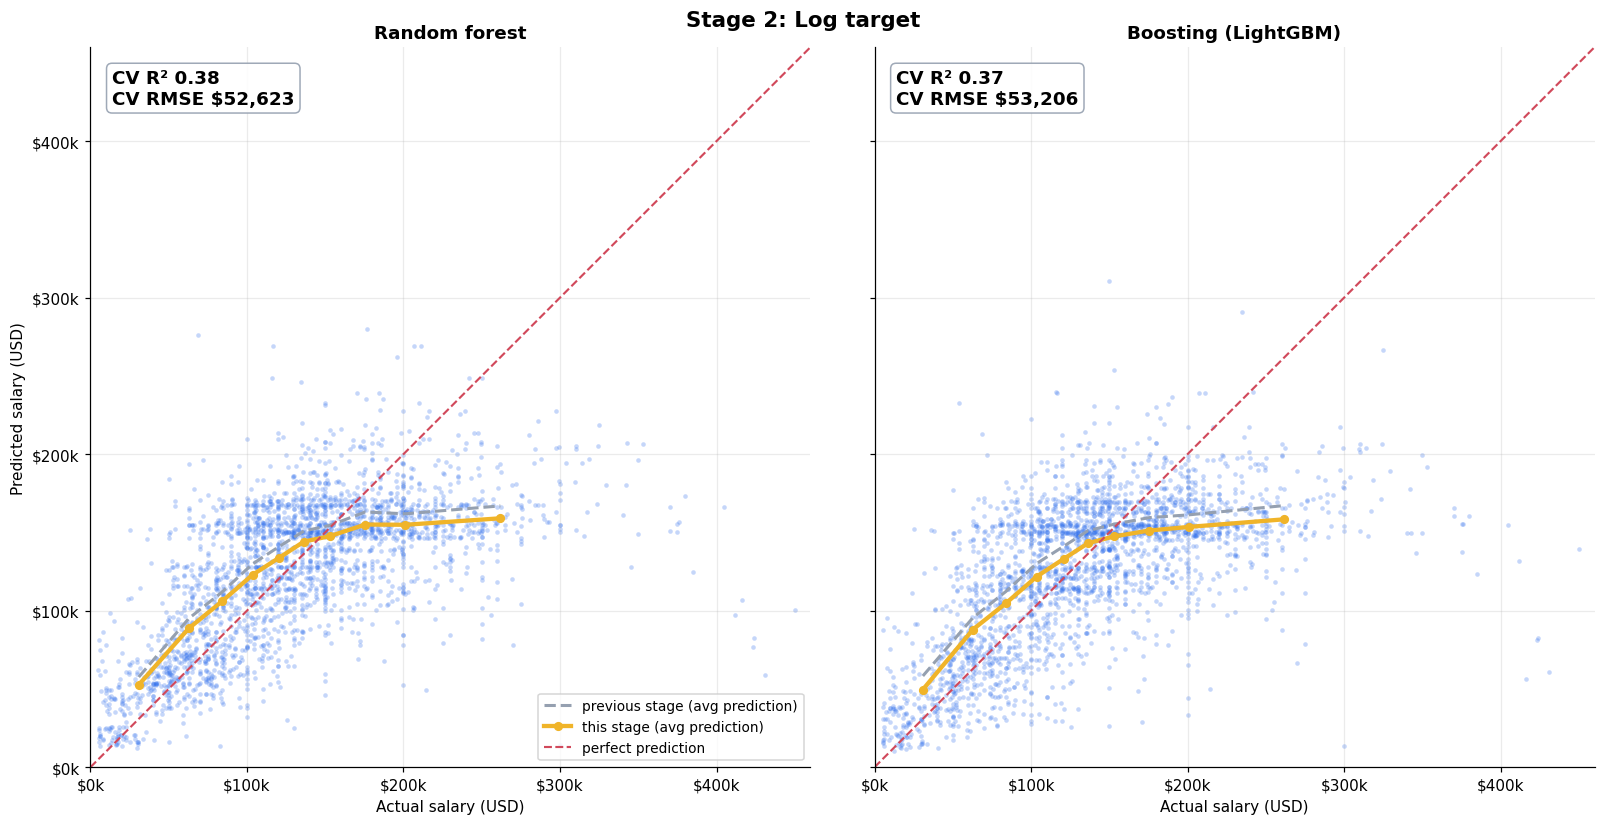

**Result (**hurt**):** **Random forest:** RMSE \$52,623 (+267), R² 0.382 (-0.006) | **Boosting:** RMSE \$53,206 (+804), R² 0.368 (-0.019)  
Tree models gain nothing from the log transform here, and converting back adds a little bias. We keep it because it helps the linear and neural models in the model search.

#### Stage 3: cleaning and features
**What we did (learned on training folds only):** collapsed job titles and locations with fewer than 10 rows, added job family, region and a level ordinal, and trimmed the top and bottom 1% of salaries **when fitting** (never when scoring).

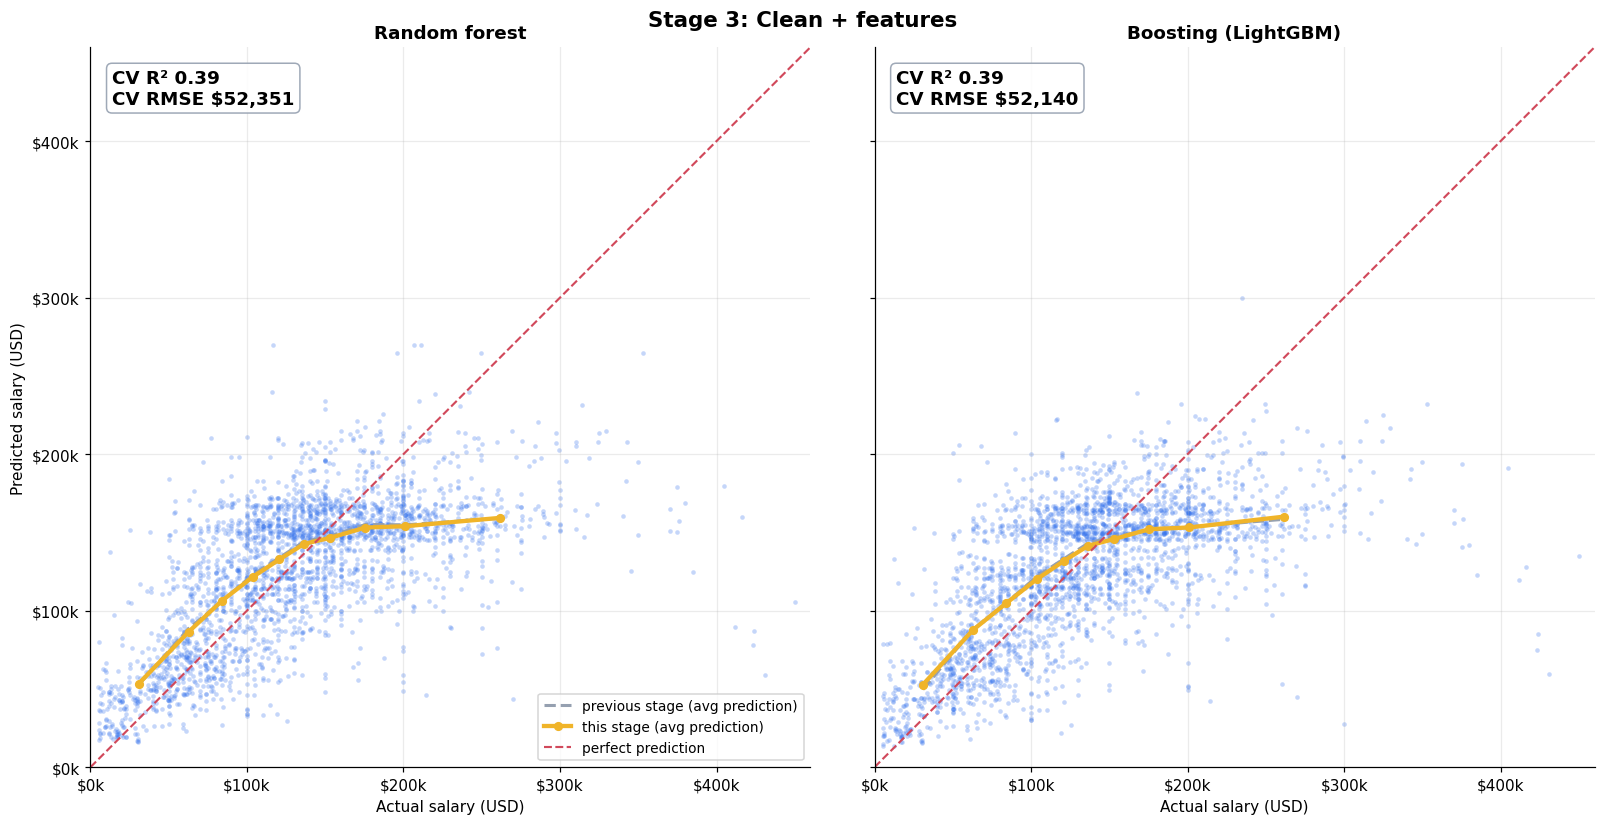

**Result (**helped**):** **Random forest:** RMSE \$52,351 (-271), R² 0.389 (+0.006) | **Boosting:** RMSE \$52,140 (-1,066), R² 0.394 (+0.026)  
Grouping rare categories gives the model fewer, better-supported categories to learn from. The effect is modest.

#### Stage 4: hyperparameter tuning
**What we did:** randomized search over tree depth, learning rate, regularisation and so on, run *inside* each fold (nested cross-validation) so the search never sees the rows it is scored on.

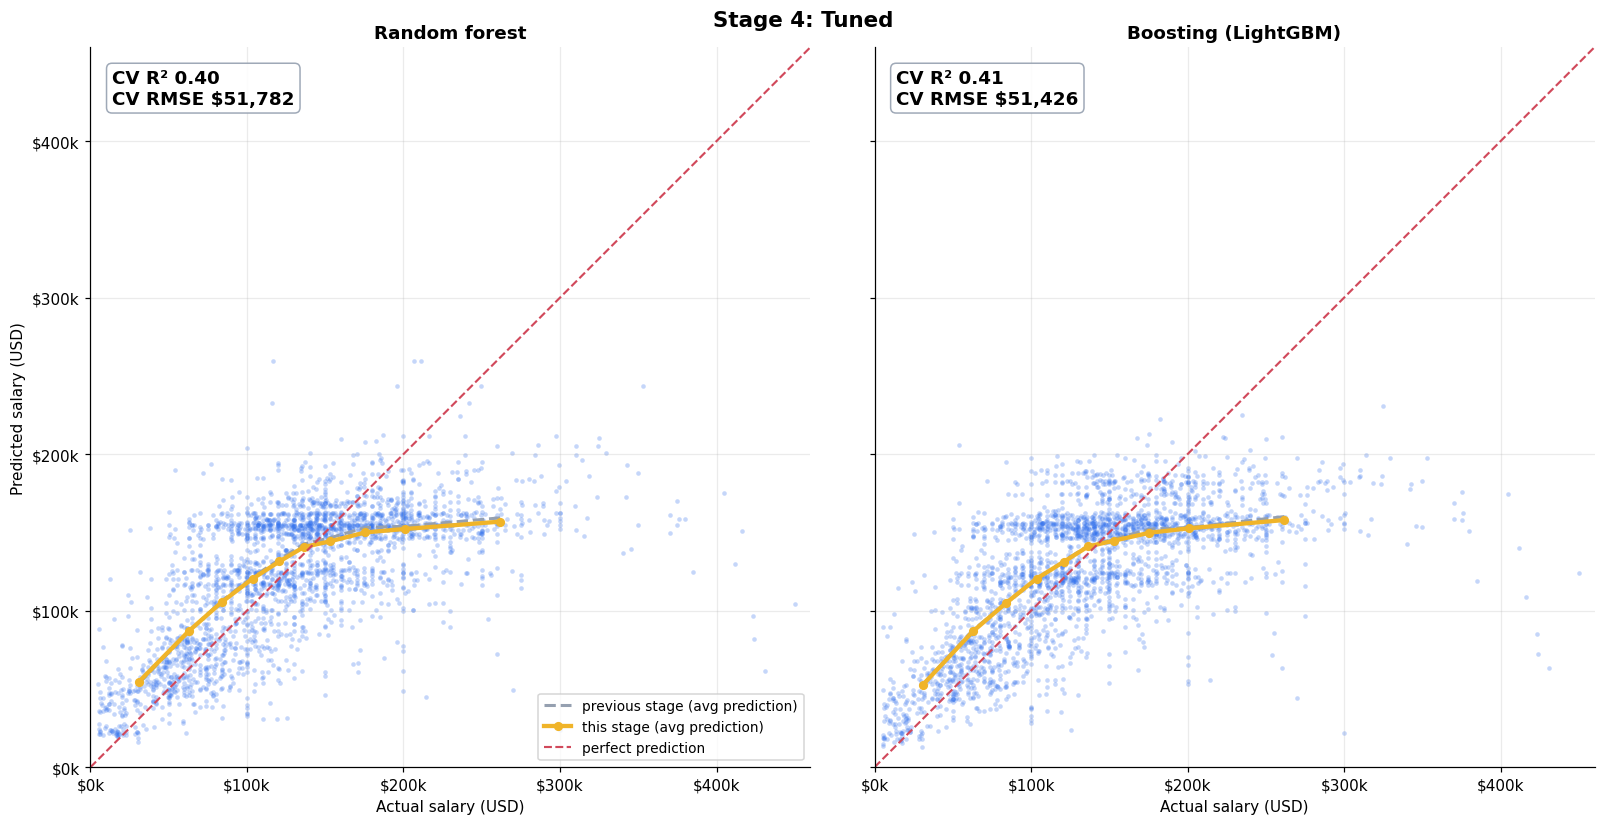

**Result (**helped**):** **Random forest:** RMSE \$51,782 (-569), R² 0.402 (+0.013) | **Boosting:** RMSE \$51,426 (-714), R² 0.410 (+0.016)  
Tuning helps both families, by a few hundred dollars of RMSE: real, but small next to the noise in the data.

#### Stage 5: the best model from the search
**What we did:** compared ten model families under the same protocol and picked by the rule in section 6. The plot shows the accuracy winner on the same held-out rows.

**Result:** Stacking: RMSE \$51,366 (-60 vs tuned boosting), R² 0.411. The whole 10-family search changes the answer by roughly the width of the fold-to-fold noise: the data, not the algorithm, sets the limit (section 6).

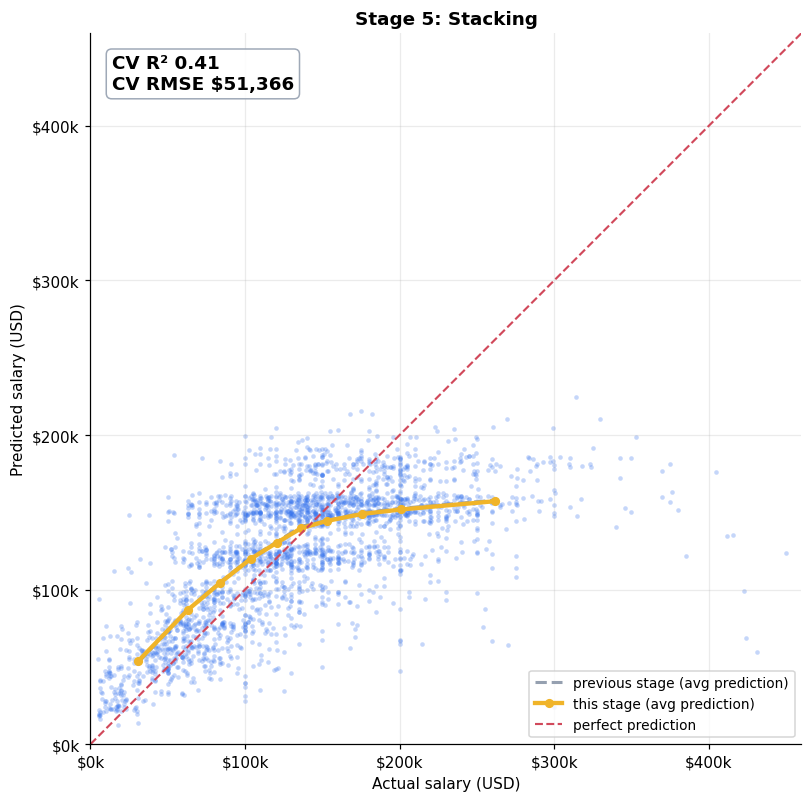

## 4. Why the R plots hugged the diagonal, and why these do not

**Training fit versus held-out fit.** The original R report plotted predictions on the training data. A flexible model can memorise the rows it trains on, so those plots look excellent. The panels below fit the same models on all rows and plot (left) predictions for rows the model has seen against (right) honest out-of-fold predictions.

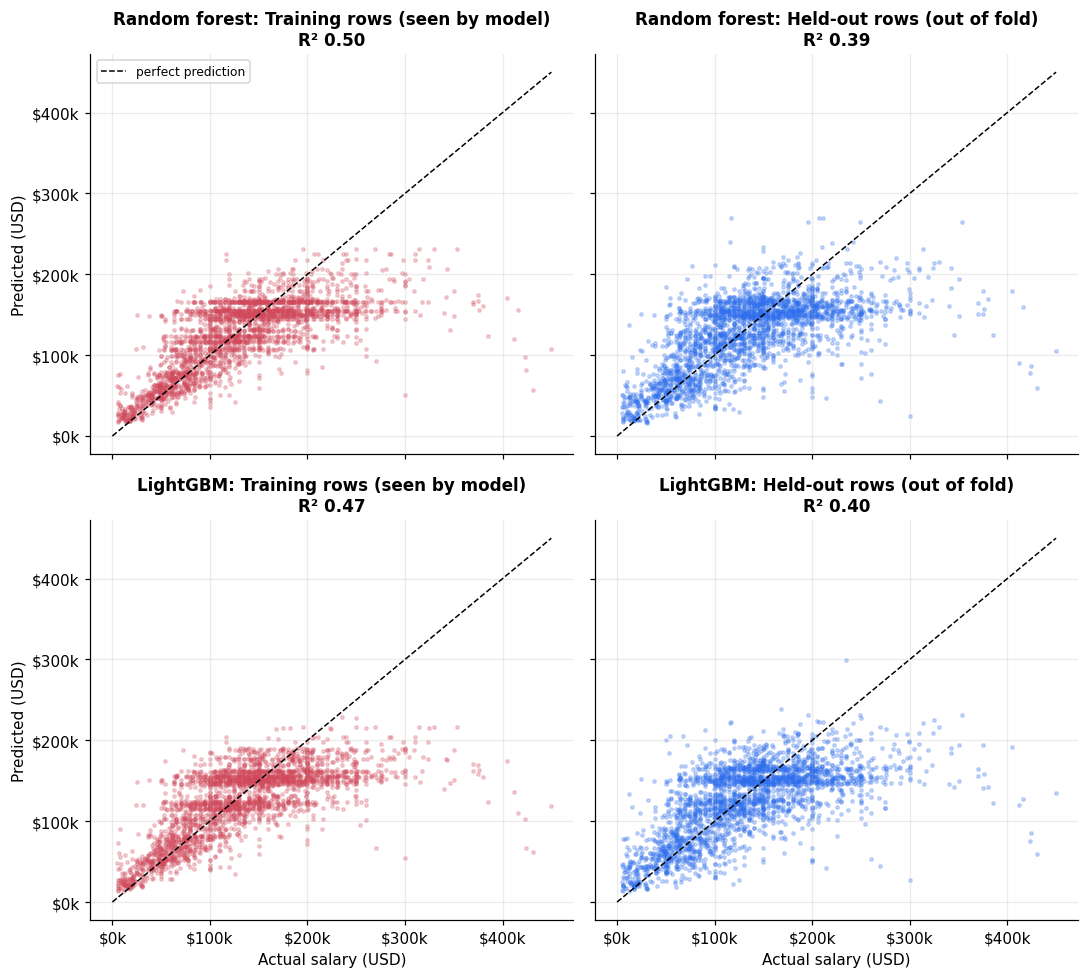

**Irreducible noise.** Take every group of people with an identical profile (same title, level, location, company size, employment type, year and remote ratio) and measure how far apart their salaries are. If a model could not tell them apart, this spread is the best it could ever explain.

People with the *same* profile typically differ by **30%** (std/mean). For the largest group above, the same title, level, location, size and year range from \$65,000 to \$310,000. A model that sees only these columns cannot do better than the group average, so held-out predictions will always fan out around the diagonal.

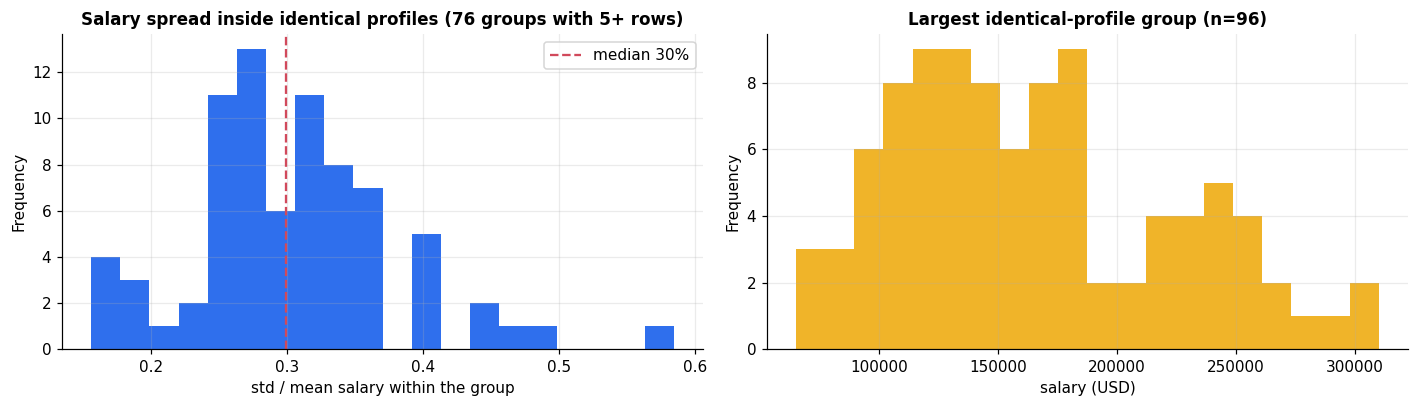

**Why predictions form horizontal bands.** With only seven features there are a few hundred distinct profiles, so many rows receive nearly identical predictions. The bands in the scatter plots are those profile averages, not an artefact.

## 5. Model search
Everything below uses the same cleaned pipeline and the same 15 folds. Each model is shown at sensible defaults and tuned with nested cross-validation (the search never sees the outer test fold).

Candidates: **ridge** (linear), **KNN**, **random forest**, **extra trees**, then the boosting family: **HistGradientBoosting**, **XGBoost**, **LightGBM**, **CatBoost** (built for categorical features), a small **neural net (MLP)**, and a **stacking** blend of ridge, random forest and LightGBM. TabPFN was not tested: it needs a pretrained weights download, so the scikit-learn MLP stands in as the neural option.

> **Note: CatBoost was evaluated at its default settings only.** Its nested tuning run was stopped after about 5 minutes because it needed roughly 25 more (it is the slowest model here), so there is no "tuned" CatBoost point below. Its default is already tied with the best model, so tuning is unlikely to change the conclusion, but a tuned CatBoost remains untested.

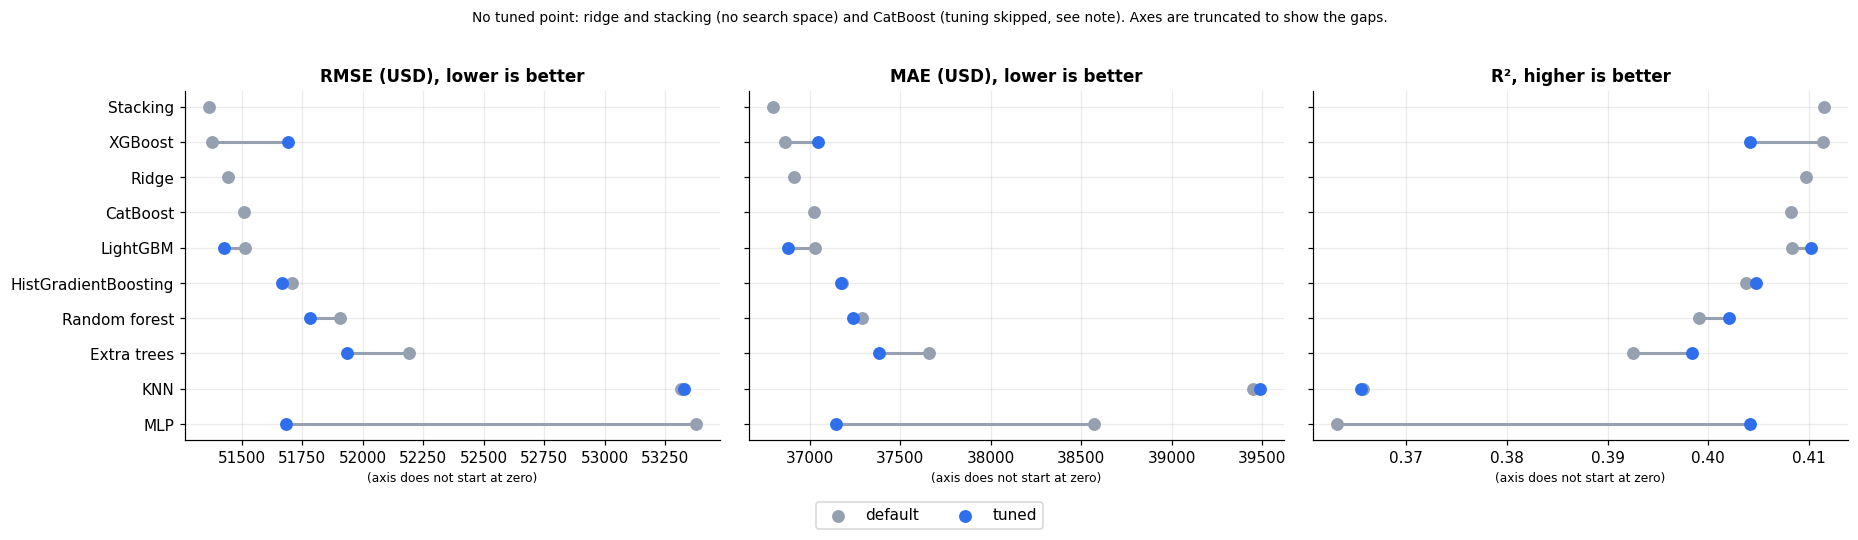

Tuning moves most models by only a few hundred dollars (the neural net, which starts furthest behind, gains the most), and several tuned models score *worse* than their defaults on held-out folds, a sign that the search is partly fitting noise. The top of the table sits within about \$1,000 of each other.

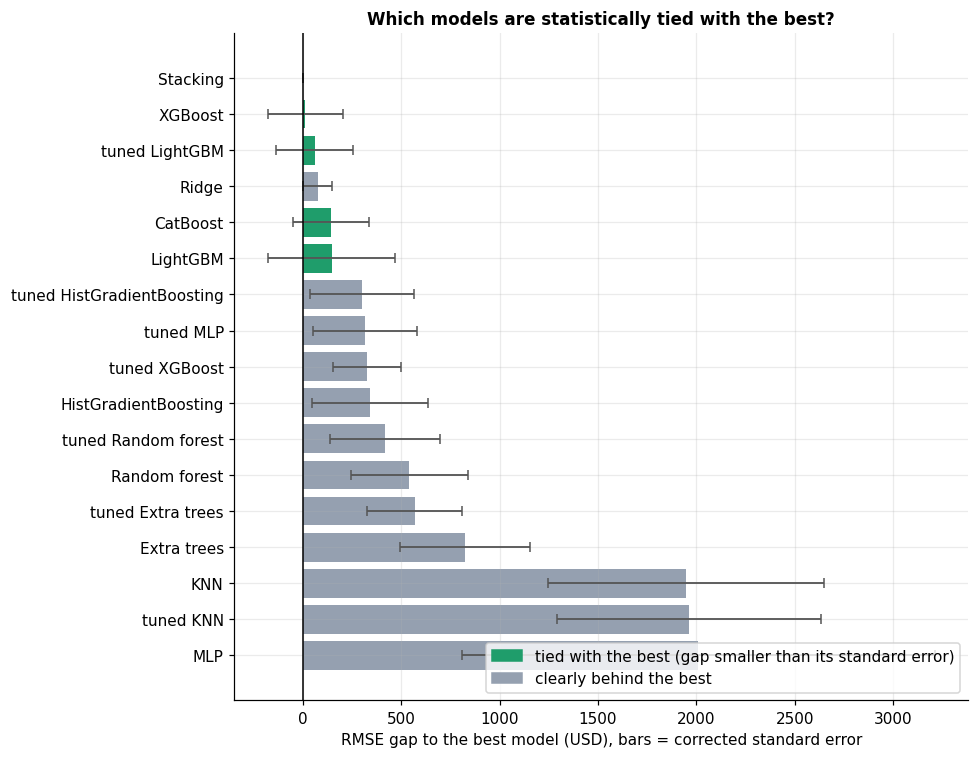

## 6. The decision rule (fixed in advance)
1. The **accuracy winner** is the model with the lowest mean held-out RMSE.
2. Any model whose paired fold-by-fold gap to the winner is smaller than its (corrected resampled) standard error is **tied**: the data cannot separate them.
3. Among tied models, prefer **the simplest** (a linear model beats a boosted ensemble when accuracy is equal).
4. For the *product* (the web app), pick the simplest tied model that can output a calibrated 10-90% range natively.

| Role | Model | Why |
|---|---|---|
| **Accuracy winner** | **Stacking** | lowest mean RMSE (\$51,366) |
| **Parsimonious pick** | **XGBoost** | simplest of the 5 models tied with the winner |
| **Product pick** | **XGBoost** | simplest tied model with native 10-90% quantile output |


model,tuned,rmse,mae,r2,gap_to_best,gap_se,tied,interval_capable,seconds
Stacking,False,"51,366","36,798",0.411000,0,0,True,False,31.000000
XGBoost,False,"51,379","36,864",0.411000,12,191,True,True,1.000000
LightGBM,True,"51,426","36,879",0.410000,60,195,True,True,23.000000
Ridge,False,"51,442","36,914",0.410000,75,75,False,False,0.000000
CatBoost,False,"51,510","37,022",0.408000,144,195,True,True,59.000000
LightGBM,False,"51,512","37,031",0.408000,146,322,True,True,0.000000
HistGradientBoosting,True,"51,666","37,171",0.405000,300,264,False,True,49.000000
MLP,True,"51,683","37,142",0.404000,317,264,False,False,65.000000
XGBoost,True,"51,691","37,044",0.404000,324,173,False,True,16.000000
HistGradientBoosting,False,"51,708","37,178",0.404000,342,294,False,True,1.000000


model,coverage,median_width,pinball
LightGBM,76.9%,"115,402","8,555"
HistGradientBoosting,76.5%,"115,693","8,605"
XGBoost,77.6%,"118,012","8,614"
CatBoost,76.6%,"117,615","8,655"


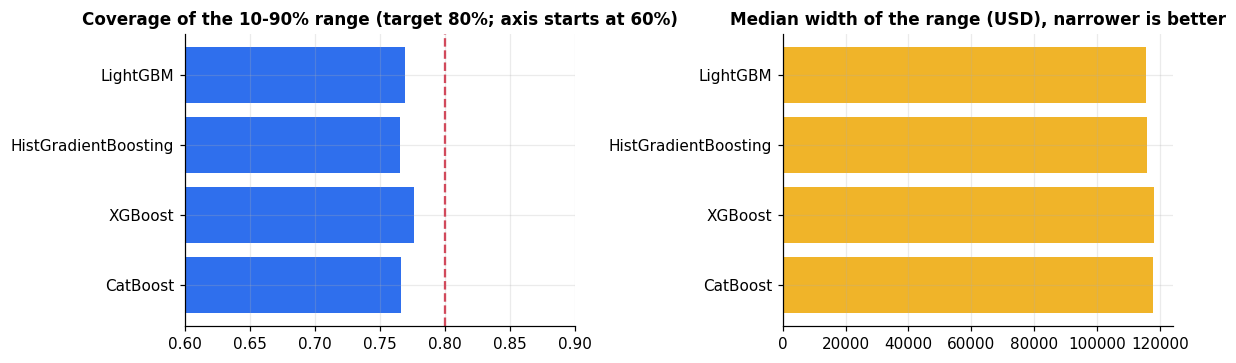

### Decision
- **No model is clearly better than the others.** 5 of 18 configurations are statistically tied with the best, spanning only \$146 of RMSE (0.3%).
- **Accuracy:** the lowest error belongs to **Stacking**, but a stacked ensemble of three models costs 30 s versus under 1 s for the alternatives and gains \$12 over the simplest tied model, **XGBoost**. By the rule, that is the pick.
- **A near-tie worth knowing about:** plain **ridge regression** misses the cutoff by under a dollar (gap \$75 vs standard error \$75), so by the strict rule it is not tied. In practice it is indistinguishable (0.15% behind the best), is far simpler, and is the most interpretable model. If explanations matter more than the last \$75, ridge is the better choice; section 8's premium analysis uses a linear model of the same kind.
- **Product (a *range*, not one number):** the rule's pick is **XGBoost**. On the 10-90% range, however, **LightGBM** has the lowest pinball loss (\$8,555) and the web app already uses LightGBM quantile models (coverage 76.9%, median width \$115,402). The four quantile models differ by only 1.2% on pinball loss, so we **keep LightGBM in the app as a deliberate exception to the rule**: the rule did not score interval quality, and the app's intervals were validated separately.
- **More modelling effort will not help; more information will.** Adding features (skills, industry, tenure, company name) is the only lever left.


## 7. The chosen model in detail

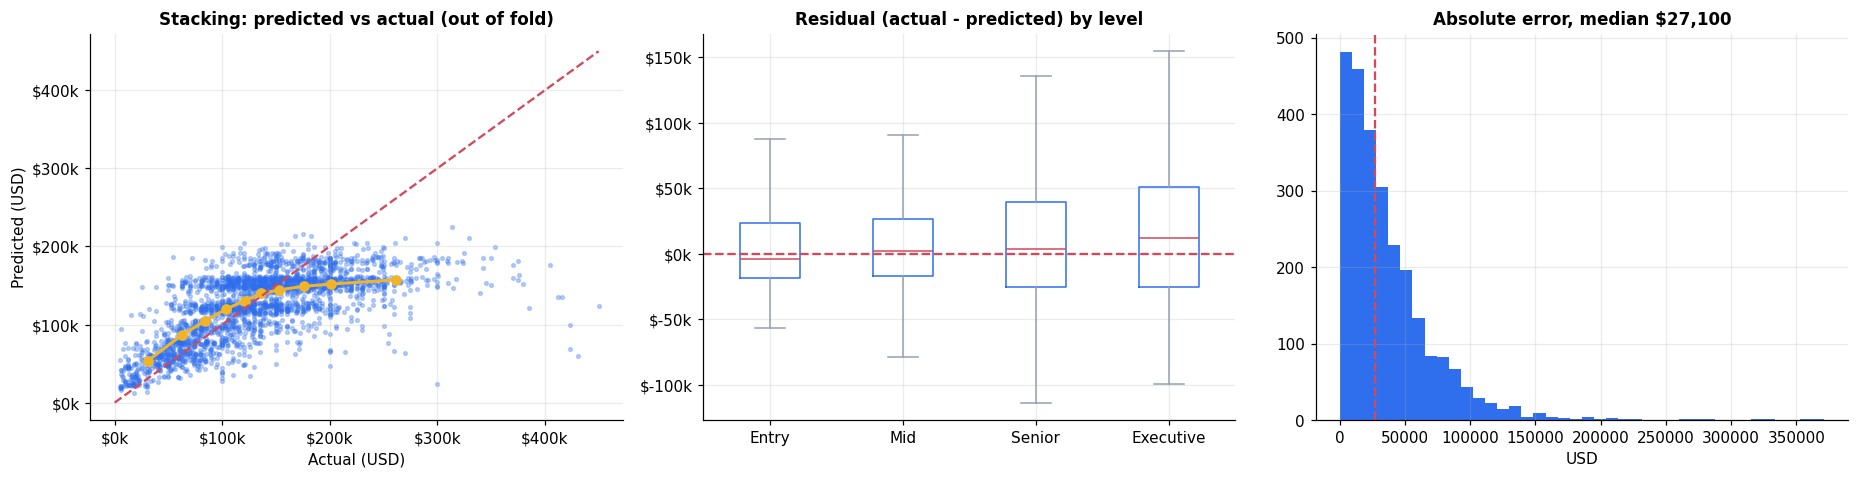

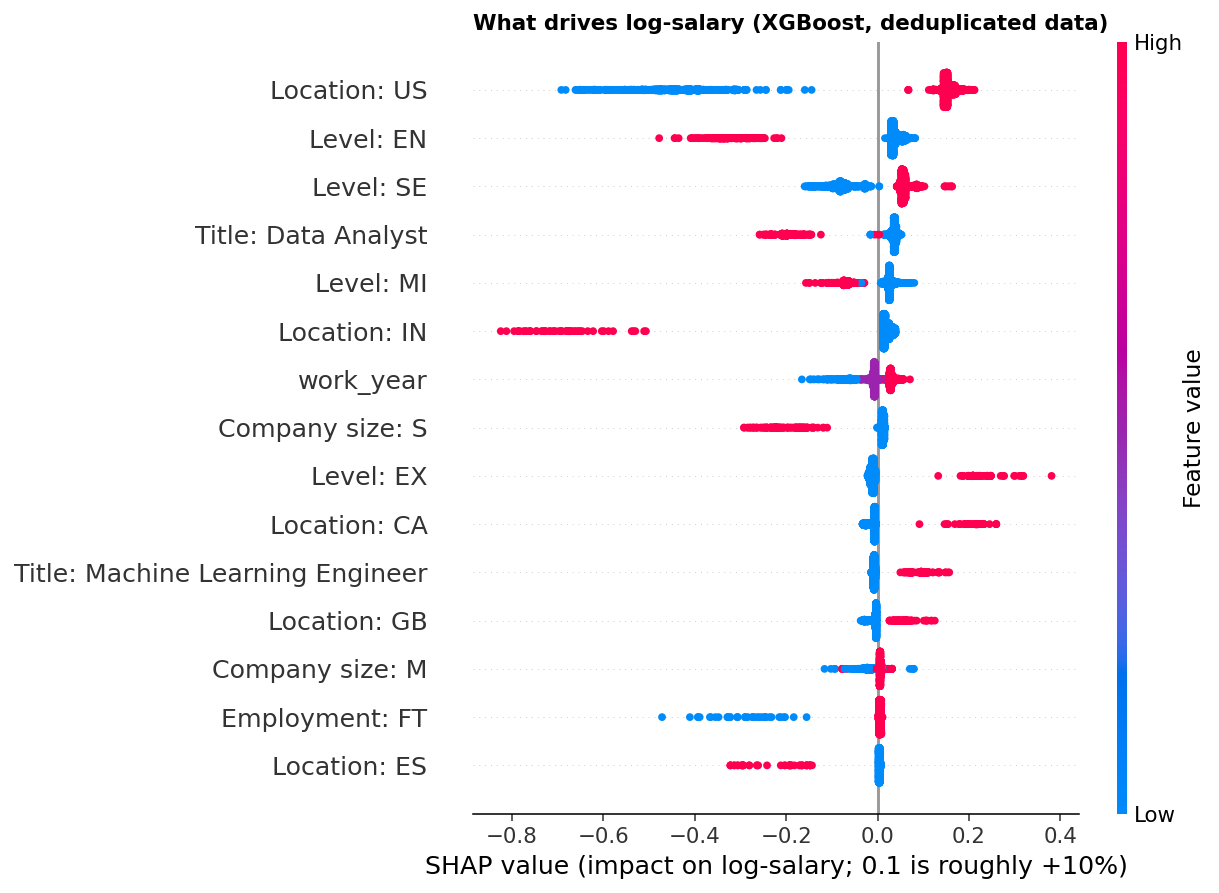

A US company location is the largest single effect; entry level pulls salary down, senior and executive levels push it up. These are associations in a survey sample, not causes.

The 10-90% quantile range covers **77.5%** of held-out salaries (target 80%).

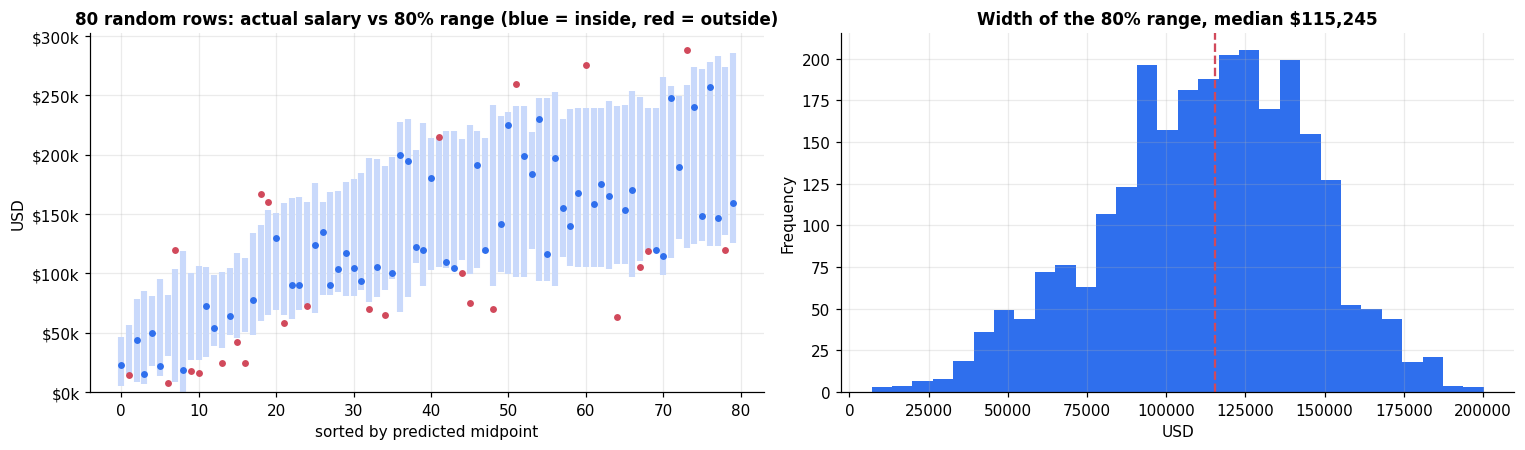

## 8. What the business can do with this

Raw prediction accuracy is modest (R\u00b2 about 0.4), so the value is not in quoting one salary. It is in **benchmarking**: knowing the typical range for a role, how big each factor is, and where the data is too thin to trust.

### 8.1 How much does each factor move pay?
Each bar is the percentage difference in salary, holding the other factors constant, from a log-salary linear model with 300 bootstrap resamples (90% interval). Grey bars cross zero: no reliable effect.

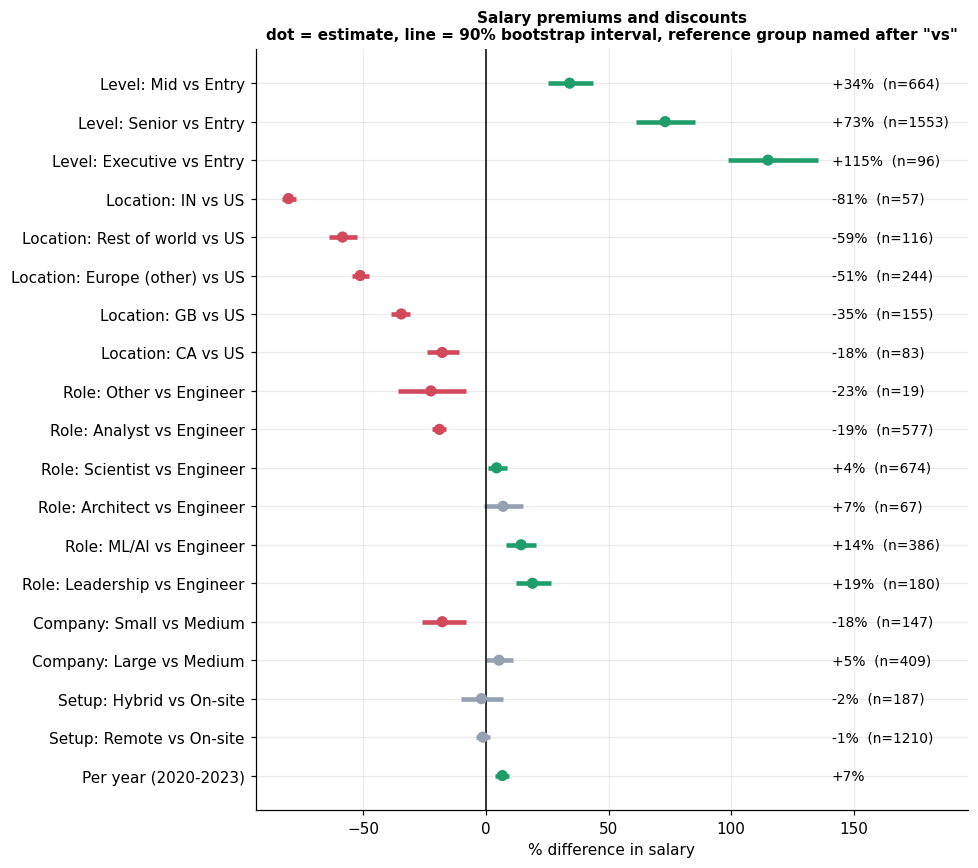

**Reading the chart**
- **Location is the dominant lever.** Compared with a US company, the same role pays about 35% less in the UK, 51% less elsewhere in Europe and 81% less in India.
- **Seniority compounds:** mid +34%, senior +73%, executive +115% versus entry level.
- **Role matters less than level or location:** analysts earn 19% less than engineers; ML/AI roles +14% and leadership +19%.
- **Remote work shows no pay penalty or premium** (fully remote -1%, interval spans zero): remote is not a cost lever on salary alone.
- **Small companies pay 18% less** than medium ones; large companies are not reliably different.
- **Market drift:** about +7% per year across 2020-2023.


### 8.2 Pay bands by role, level and market
Median salary in thousands of USD where at least 10 people are in the cell. Use the band (25th-75th percentile) in the table below, not the single median, when setting or checking a salary.

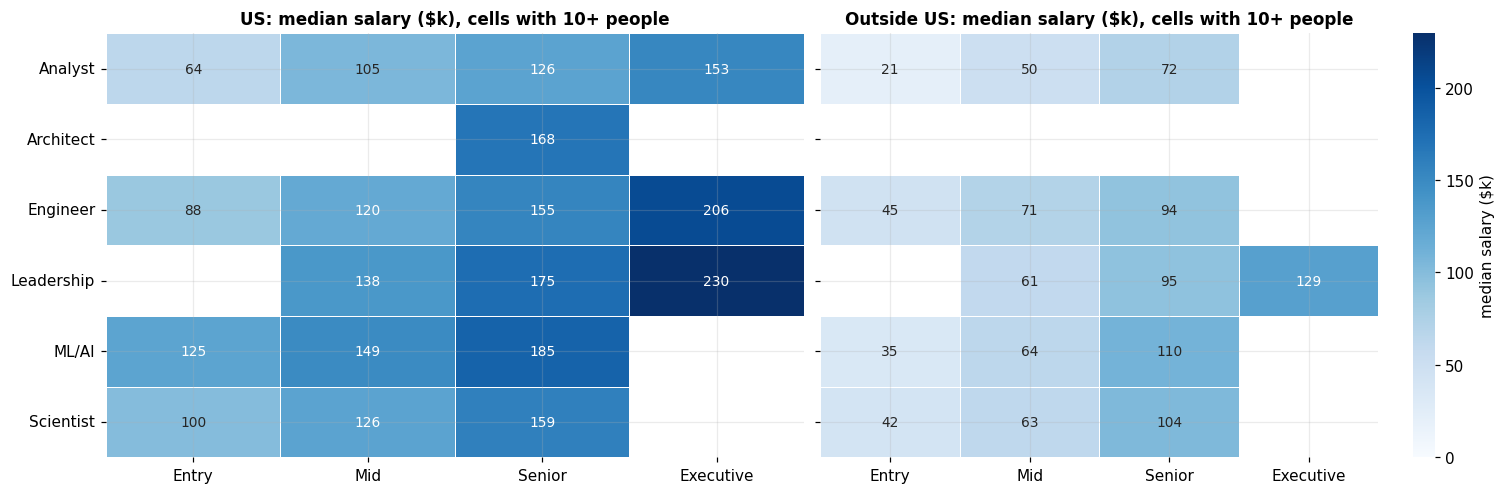

Role family,Level,People,Median,Middle 50% band
Engineer,Executive,36,"$206,000","$163,350 to $239,750"
ML/AI,Senior,153,"$184,590","$145,000 to $214,000"
Leadership,Senior,83,"$175,000","$140,050 to $202,250"
Architect,Senior,54,"$168,250","$125,750 to $209,694"
Scientist,Senior,362,"$159,150","$134,077 to $200,000"
Engineer,Senior,384,"$155,000","$122,450 to $194,250"
ML/AI,Mid,64,"$149,250","$118,075 to $183,475"
Scientist,Mid,84,"$126,250","$100,000 to $151,508"
Analyst,Senior,289,"$125,600","$104,300 to $156,400"
Engineer,Mid,95,"$120,000","$97,050 to $153,500"


### 8.3 Where can this be trusted?
Coverage is how often the real salary fell inside the model's 80% range, out of fold. A segment near 80% is well calibrated; the number of people (n) shows how much data stands behind it.

**Least well calibrated segments (30+ people):** Location: Rest of world 70% (n=116), Location: IN 74% (n=57), Role: ML/AI 74% (n=386), Location: CA 75% (n=83), Level: Entry 75% (n=270). The model undercovers where data is thin or pay is unusually low or high.

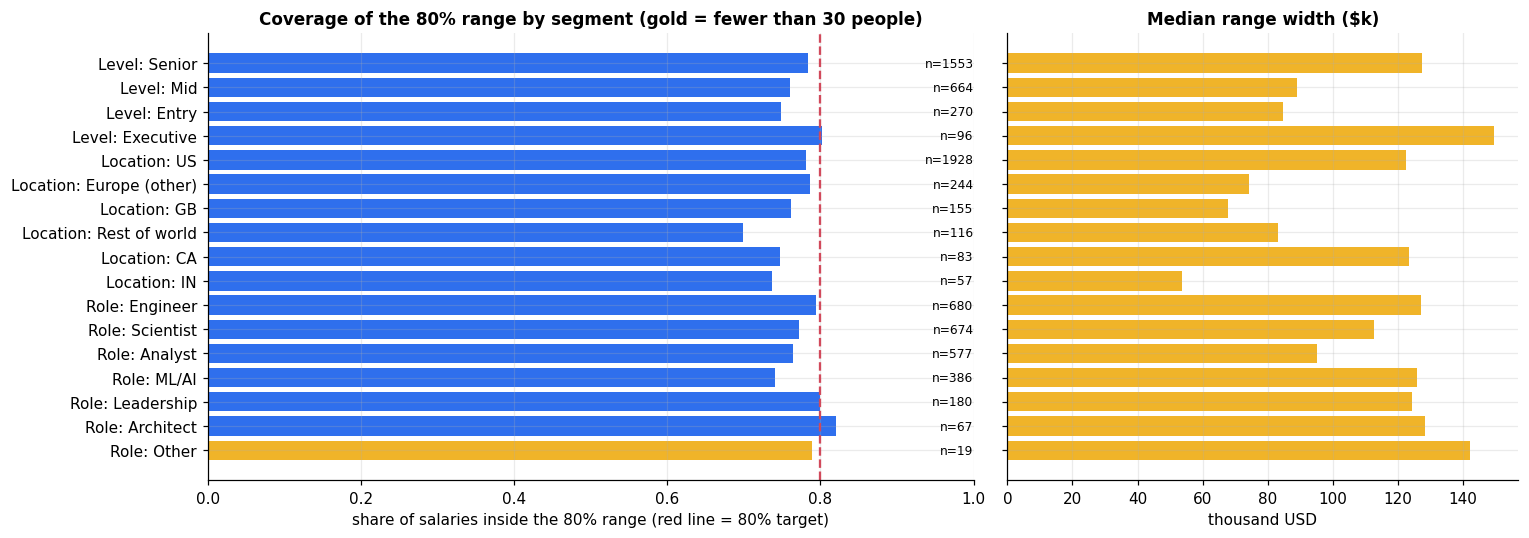

### 8.4 Decisions this supports

| Business question | How to use the analysis | Confidence |
|---|---|---|
| **Set or review a pay band** for a role | Start from the 25-75% band for the role family, level and market (8.2); adjust for company size (about -18% for small firms) | High where n is large (US engineers, scientists, analysts) |
| **Check an offer** | Enter the profile in the web app; treat the 10-90% range as plausible and an offer below it as a retention or fairness flag | Medium: ranges are wide (median \$115,245) |
| **Where to hire** | Location is the biggest cost driver (8.1). The data supports quantifying the gap, not judging output or quality | High for UK, Europe, India; low for thin locations |
| **Remote policy** | Remote work shows no reliable salary penalty or premium (-1%), so going remote does not by itself change what you must pay | Medium: remote is a self-reported field |
| **Career-ladder budgeting** | Plan for about +34% (entry to mid) and +73% (entry to senior) | High |
| **Forecasting wage inflation** | About +7% a year in this sample | Low: four years, survey sample |


### 8.5 Limits to state out loud
- **Self-reported survey, 2020-2023, USD.** Not a payroll dataset, and not current.
- **Seven columns only.** No skills, tenure, industry, company name or education, which is why R\u00b2 stops near 0.4.
- **Associations, not causes.** Location "effects" bundle cost of living, taxes and labour markets.
- **Thin segments** (grey bars above) should not drive decisions.
- **A range is not an offer.** Use the model to frame a conversation, not to set an individual's pay.

## 9. Summary
1. The original R result was inflated by duplicate rows and, in places, by evaluating on training data.
2. Cleaning, features and tuning improve held-out error by a few percent, not a transformation. The plots move toward the diagonal but cannot reach it because identical profiles differ by about 30%.
3. Ten model families were tested. Their accuracy is statistically indistinguishable, so the rule picks the simplest model for accuracy and a quantile boosting model for the range-based product.
4. The business value is in benchmarking: location, level and role premiums, pay bands, and an honest view of where the data is too thin to trust.